# Discounting Pension Liabilities and Liability-Driven Investing: the High-Quality Corporate Curve vs Treasuries, Key-Rate Hedges and Machine-Learned Hedge Ratios

A pension promise is a long stream of payments, and its value today depends almost entirely on the interest rate used to discount it. When rates fall, the promise becomes more expensive overnight, even though nothing about the members has changed. This notebook measures how much the choice of discount curve matters, and how well different bond portfolios protect a plan against those swings.

**What it does.** It values the benefit payments of three frozen defined-benefit plans (mostly retirees, mature, and young) every month since 1984 on the high-quality corporate (HQM) spot curve, a common reference for U.S. pension accounting. It then compares four discounting bases (the full curve, a single equivalent rate, Treasuries and minimum-funding segment rates) and backtests six hedging strategies from 2008 to 2026:

1. no hedge (cash);
2. a single 10-year Treasury zero matched on duration;
3. Treasury zeros matched on key-rate durations;
4. a rolling minimum-variance hedge with Treasuries and corporate bonds;
5. a ridge regression that learns corrections to the key-rate hedge;
6. a neural network that sets the corrections from the state of the market.

**Data.** FRED: the HQM corporate spot curve from 6 months to 100 years, Treasury constant-maturity yields and the 3-month bill. Yahoo Finance: the iShares investment-grade corporate bond ETF (LQD).

**Methods.** Gompertz–Makeham survival, curve valuation, single equivalent rates, effective and key-rate durations, and Treasury curve bootstrapping. The hedges are a walk-forward rolling OLS, a ridge regression and a Keras network trained on the surplus tracking error.

**Key output.** Liability values and durations under each discount basis, the funded-status volatility each basis implies, and the surplus tracking error of each hedge, including 2008 and 2022.

## 1. Discounting a pension promise

A frozen defined-benefit plan owes a known schedule of payments $CF_t$, as long as members survive. Its liability is the present value

$$L=\sum_t CF_t\,\big(1+z(t)/2\big)^{-2t},$$

where $z(t)$ is the spot rate for maturity $t$ on the chosen curve.

**Which curve?** The rules differ by purpose:

- **Accounting** (IAS 19, ASC 715) uses yields on high-quality corporate bonds. In the United States the Treasury's **HQM curve**, built from AA-rated and nearby bonds and extrapolated to 100 years, is a common reference.
- **Minimum funding** under U.S. pension law uses three **segment rates** (0–5, 5–20 and 20+ years) taken from a 24-month average of the same corporate curve.
- **Settlement and insurer pricing** often start from Treasuries plus a spread.

**Single equivalent rate (SER).** It is the one flat rate that gives the same present value as the full curve. It is what sponsors report.

**Duration.** The liability's sensitivity to rates is its duration $D=-\frac{1}{L}\frac{\partial L}{\partial y}$. A plan with duration 12 loses or gains about 12% of its value for each point the discount rate moves.

**Key-rate durations** split that sensitivity across points of the curve (2, 5, 10, 20 and 30 years), so a hedge can match the shape as well as the level.

**Liability-driven investing (LDI)** holds assets whose value moves like the liability. The surplus (assets minus liabilities) then stays stable. Two risks remain even with a perfect Treasury hedge:

- the **credit spread** between the corporate discount curve and Treasuries;
- **curve shape** moves that a single duration number misses.

**Machine learning** enters through the hedge ratios. An analytic hedge assumes spreads do not move. A regression or a network trained on past liability returns can learn how much extra duration, and how much corporate credit, actually tracked the liability best. The question is whether that survives out of time.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import keras
import torch
import yfinance as yf
from scipy.optimize import brentq
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import TimeSeriesSplit

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 7
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

# Gompertz-Makeham mortality of the Standard Ultimate Survival Model
MAKEHAM_A, MAKEHAM_B, MAKEHAM_C = 0.00022, 2.7e-6, 1.124
RET_AGE, MAX_AGE = 65, 120
KEY_TENORS = [2, 5, 10, 20, 30]
TEST_START = "2008-01"

print(
    f"keras {keras.__version__} · torch {torch.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

/home/claude/pkg0/venv/lib/python3.12/site-packages/torch/cuda/__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


keras 3.15.1 · torch 2.14.1+cu130 · run on 2026-10-28


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data

- **HQM corporate spot curve:** 200 monthly FRED series, from 6 months (`HQMCB6MT`) to 100 years (`HQMCB100YR`) in half-year steps, since January 1984. The rates are monthly averages, quoted as semi-annual bond-equivalent spot rates.
- **Treasury par yields:** constant-maturity yields at 1, 2, 3, 5, 7, 10, 20 and 30 years (`GS1` … `GS30`), also monthly averages. The 20-year series has a gap in 1987–1993 and the 30-year in 2002–2006; both are filled by linear interpolation across the curve.
- **Cash:** the 3-month Treasury bill (`TB3MS`).
- **Corporate bonds:** daily adjusted prices of LQD since 2002. They are averaged by month so that their returns line up with the monthly-average yields.

In [3]:
HQM_TENORS = [0.5] + [x / 2 for x in range(2, 201)]


def hqm_id(t):
    if t == 0.5:
        return "HQMCB6MT"
    whole, half = int(t), t % 1 > 0
    return f"HQMCB{whole}Y6M" if half else f"HQMCB{whole}YR"


def fetch_hqm():
    cols = {}
    for t in HQM_TENORS:
        cols[t] = fred.get_series(hqm_id(t))
        time.sleep(0.25)
    out = pd.DataFrame(cols)
    out.columns = [str(c) for c in out.columns]
    return out


def fetch_treasury():
    ids = ["GS1", "GS2", "GS3", "GS5", "GS7", "GS10", "GS20", "GS30", "TB3MS"]
    return pd.DataFrame({k: fred.get_series(k) for k in ids})


def fetch_lqd():
    px = yf.download(
        "LQD", start="2002-07-01", auto_adjust=True, progress=False
    )["Close"]
    px = px.iloc[:, 0] if isinstance(px, pd.DataFrame) else px
    return px.rename("lqd").to_frame()


HQM = cached("hqm_spot_curve", fetch_hqm, max_age_hours=24 * 7) / 100
HQM.columns = [float(c) for c in HQM.columns]
HQM.index = pd.to_datetime(HQM.index).to_period("M")
HQM = HQM.dropna()
TSY = cached("treasury_cmt", fetch_treasury, max_age_hours=24 * 7) / 100
TSY.index = pd.to_datetime(TSY.index).to_period("M")
TSY = TSY.loc["1984-01":]
LQD_D = cached("lqd_daily", fetch_lqd, max_age_hours=24)
LQD_D.index = pd.to_datetime(LQD_D.index)
LQD_M = LQD_D["lqd"].groupby(LQD_D.index.to_period("M")).mean()

print(
    f"HQM curve: {HQM.shape[1]} tenors · {HQM.index.min()} → {HQM.index.max()}"
)
print(
    f"Treasury: {TSY.index.min()} → {TSY.index.max()} · "
    f"LQD monthly averages: {LQD_M.index.min()} → {LQD_M.index.max()}"
)
print("HQM spot rates (%) at selected maturities:")
(HQM[[1.0, 5.0, 10.0, 30.0, 100.0]].iloc[[0, 120, 240, 360, -1]] * 100).round(
    2
)

HQM curve: 200 tenors · 1984-01 → 2026-09
Treasury: 1984-01 → 2026-09 · LQD monthly averages: 2002-07 → 2026-10
HQM spot rates (%) at selected maturities:


,1.00,5.00,10.00,30.00,100.00
1984-01,11.14,12.09,12.89,9.99,8.38
1994-01,4.01,5.70,6.54,7.97,8.59
2004-01,1.53,3.84,5.18,6.69,7.29
2014-01,0.43,2.34,4.20,5.33,5.59
2026-09,4.66,5.38,5.86,6.68,6.93


## 4. Three frozen plans and their benefit payments

The member data are stylised, because plan-level census data are not public. Each plan pays a flat nominal pension of 1 a year from age 65 for life, with no new accruals:

- **Retiree plan:** pensioners aged 65–100, weighted by survivorship from 65 (a mature, closed book).
- **Mature plan:** the same pensioners plus deferred members aged 35–64. Their accrued pension grows with service, $(x-25)/40$.
- **Young plan:** deferred members aged 25–60 only, the profile of a recently frozen corporate plan.

Survival follows the Gompertz–Makeham law of the Standard Ultimate Survival Model, $\mu_x=A+Bc^x$ (Dickson, Hardy and Waters). Payments are made mid-year.

In [4]:
AGES = np.arange(0, MAX_AGE + 1)


def surv(x, t):
    """t-year survival probability from exact age x under Makeham's law."""
    lnc = np.log(MAKEHAM_C)
    return np.exp(
        -MAKEHAM_A * t - MAKEHAM_B / lnc * MAKEHAM_C**x * (MAKEHAM_C**t - 1)
    )


def cash_flows(members):
    """members: list of (age, accrued pension, count) -> payments at t+0.5."""
    years = np.arange(0, MAX_AGE - 20)
    cf = np.zeros(len(years))
    for age, ben, n in members:
        t = years + 0.5
        pay = (age + t >= RET_AGE) & (age + t <= MAX_AGE)
        cf += n * ben * pay * surv(age, t)
    keep = cf > 1e-6 * cf.max()
    return pd.Series(cf[keep], index=(years + 0.5)[keep])


retirees = [(x, 1.0, surv(RET_AGE, x - RET_AGE)) for x in range(65, 101)]
deferred = [(x, (x - 25) / 40, 1.0) for x in range(35, 65)]
young = [(x, (x - 22) / 43, 1.0) for x in range(25, 61)]
PLANS = {
    "Retiree plan": cash_flows(retirees),
    "Mature plan": cash_flows(retirees + deferred),
    "Young plan": cash_flows(young),
}
for k, cf in PLANS.items():
    cf /= cf.sum()  # scale: total undiscounted payments = 1
    print(
        f"{k:13s} payments over {cf.index.max():.0f} years · "
        f"cash-weighted mean time {np.dot(cf.index, cf):.1f} years"
    )

Retiree plan  payments over 46 years · cash-weighted mean time 9.6 years
Mature plan   payments over 76 years · cash-weighted mean time 18.6 years
Young plan    payments over 84 years · cash-weighted mean time 30.3 years


## 5. Valuing the liabilities every month since 1984

For each month the spot curve is interpolated at each payment date (linearly in maturity, flat beyond 100 years). The notebook computes:

- the present value;
- the **single equivalent rate**, by root-finding;
- the **effective duration**, from a ±10 bp parallel shift;
- the **key-rate durations**, from triangular 1 bp bumps centred on 2, 5, 10, 20 and 30 years (the 30-year bump stays flat beyond 30).

In [5]:
HQM_T = np.array(HQM.columns, dtype=float)


def spot_at(curve_row, times, tenors):
    return np.interp(times, tenors, curve_row)


def pv(cf_t, cf_v, curve_row, tenors, shift=None):
    z = spot_at(curve_row, cf_t, tenors)
    if shift is not None:
        z = z + shift(cf_t)
    return np.sum(cf_v * (1 + z / 2) ** (-2 * cf_t))


def key_bump(k):
    """Triangular 1 bp bump centred on key tenor k."""
    kt = KEY_TENORS
    i = kt.index(k)
    lo = kt[i - 1] if i > 0 else 0.0
    hi = kt[i + 1] if i < len(kt) - 1 else None

    def f(t):
        up = np.clip((t - lo) / (k - lo), 0, 1)
        if hi is None:
            return 1e-4 * np.where(t <= k, up, 1.0)
        down = np.clip((hi - t) / (hi - k), 0, 1)
        return 1e-4 * np.where(t <= k, up, down)

    return f


def ser(cf_t, cf_v, value):
    g = lambda y: np.sum(cf_v * (1 + y / 2) ** (-2 * cf_t)) - value
    return brentq(g, -0.05, 0.5)


def value_history(cf, curve, tenors):
    t, v = cf.index.to_numpy(), cf.to_numpy()
    rows = []
    for per, row in zip(curve.index, curve.to_numpy()):
        p0 = pv(t, v, row, tenors)
        up = pv(t, v, row, tenors, lambda s: 1e-3 + 0 * s)
        dn = pv(t, v, row, tenors, lambda s: -1e-3 + 0 * s)
        krd = [
            (p0 - pv(t, v, row, tenors, key_bump(k))) / (p0 * 1e-4)
            for k in KEY_TENORS
        ]
        rows.append(
            [per, p0, ser(t, v, p0), (dn - up) / (2 * p0 * 1e-3), *krd]
        )
    cols = ["period", "pv", "ser", "duration"] + [
        f"krd_{k}" for k in KEY_TENORS
    ]
    return pd.DataFrame(rows, columns=cols).set_index("period")


VAL = {k: value_history(cf, HQM, HQM_T) for k, cf in PLANS.items()}
last = HQM.index.max()
SNAP = pd.DataFrame({k: v.loc[last] for k, v in VAL.items()}).T
SNAP["sum of KRDs"] = SNAP[[f"krd_{k}" for k in KEY_TENORS]].sum(axis=1)
print(f"Valuation date {last}")
SNAP.round(4)

Valuation date 2026-09


,pv,ser,duration,krd_2,krd_5,krd_10,krd_20,krd_30,sum of KRDs
Retiree plan,0.62,0.06,6.65,0.53,1.43,2.58,1.71,0.32,6.56
Mature plan,0.42,0.06,10.23,0.37,1.18,2.87,3.23,2.52,10.17
Young plan,0.19,0.06,20.71,0.00,0.30,3.11,6.99,10.29,20.68


## 6. How much does the discount basis matter?

The mature plan is valued under four bases:

1. the full HQM spot curve (the accounting reference);
2. a flat single equivalent rate from the same curve: the same value today by construction, but a different sensitivity to curve shape;
3. the Treasury spot curve, bootstrapped from par yields (the risk-free view an insurer starts from);
4. segment rates in the style of U.S. minimum funding: the HQM spot rates averaged over 0–5, 5–20 and 20+ years, then averaged over the past 24 months.

The minimum-funding basis is an approximation. The legal rates also apply an interest-rate corridor around a 25-year average, which is left out here.

In [6]:
PAR_T = np.array([1, 2, 3, 5, 7, 10, 20, 30], dtype=float)


def bootstrap_treasury(par_row):
    """Semi-annual par yields -> spot rates at 0.5..30 years."""
    grid = np.arange(0.5, 30.01, 0.5)
    par = np.interp(grid, PAR_T, par_row)
    df = np.zeros(len(grid))
    for n, c in enumerate(par / 2):
        df[n] = (1 - c * df[:n].sum()) / (1 + c)
    spot = 2 * (df ** (-1 / (2 * grid)) - 1)
    return grid, spot


par = TSY[["GS1", "GS2", "GS3", "GS5", "GS7", "GS10", "GS20", "GS30"]]
par.columns = PAR_T
par = par.interpolate(axis=1, method="index", limit_direction="both")
TSY_T = np.arange(0.5, 30.01, 0.5)
TSY_SPOT = pd.DataFrame(
    [bootstrap_treasury(r)[1] for r in par.to_numpy()],
    index=par.index,
    columns=TSY_T,
)

seg_now = HQM.rolling(24).mean()
seg_bounds = [(0, 5), (5, 20), (20, 101)]


def segment_curve(row):
    out = np.empty(len(HQM_T))
    for lo, hi in seg_bounds:
        m = (HQM_T > lo) & (HQM_T <= hi)
        out[m] = row[m].mean()
    return out


SEG = pd.DataFrame(
    [segment_curve(r) for r in seg_now.dropna().to_numpy()],
    index=seg_now.dropna().index,
    columns=HQM_T,
)

cf = PLANS["Mature plan"]
t_, v_ = cf.index.to_numpy(), cf.to_numpy()
common_idx = HQM.index.intersection(TSY_SPOT.index).intersection(SEG.index)
BASIS = pd.DataFrame(index=common_idx)
BASIS["HQM spot curve"] = [
    pv(t_, v_, HQM.loc[p].to_numpy(), HQM_T) for p in common_idx
]
BASIS["Treasury spot curve"] = [
    pv(
        t_,
        v_,
        np.r_[TSY_SPOT.loc[p].to_numpy(), TSY_SPOT.loc[p].to_numpy()[-1]],
        np.r_[TSY_T, 101.0],
    )
    for p in common_idx
]
BASIS["Segment rates (24m avg)"] = [
    pv(t_, v_, SEG.loc[p].to_numpy(), HQM_T) for p in common_idx
]
ser_m = VAL["Mature plan"]["ser"]
flat_dur = []
for p in common_idx:
    y = ser_m.loc[p]
    flat_dur.append(
        np.sum(t_ * v_ * (1 + y / 2) ** (-2 * t_ - 1))
        / np.sum(v_ * (1 + y / 2) ** (-2 * t_))
    )

ret = np.log(BASIS).diff().dropna()
BASIS_TAB = pd.DataFrame({
    "value now (HQM = 100)": (
        100 * BASIS.iloc[-1] / BASIS["HQM spot curve"].iloc[-1]
    ),
    "annualised volatility of value": ret.std() * np.sqrt(12),
    "worst 12-month change": np.log(BASIS).diff(12).min(),
    "best 12-month change": np.log(BASIS).diff(12).max(),
    "change 2021-12 → 2022-12": np.log(
        BASIS.loc[pd.Period("2022-12")] / BASIS.loc[pd.Period("2021-12")]
    ),
})
print(
    f"Single equivalent rate now {ser_m.iloc[-1]:.2%} · Macaulay duration "
    f"at the SER {flat_dur[-1]:.1f} vs effective duration on the curve "
    f"{VAL['Mature plan']['duration'].iloc[-1]:.1f}"
)
BASIS_TAB.round(3)

Single equivalent rate now 6.17% · Macaulay duration at the SER 10.7 vs effective duration on the curve 10.2


,value now (HQM = 100),annualised volatility of value,worst 12-month change,best 12-month change,change 2021-12 → 2022-12
HQM spot curve,100.00,0.07,-0.36,0.26,-0.28
Treasury spot curve,110.05,0.09,-0.31,0.27,-0.28
Segment rates (24m avg),105.97,0.02,-0.15,0.12,-0.11


## 7. Liability returns and hedge-asset returns

Each plan's payment profile is held fixed (a plan in steady state). Its monthly return is the change in value from one month of ageing and the move in the curve, plus the payments that fall due:

$$r^L_{m+1}=\frac{PV_{m+1}(CF,\;t-\tfrac1{12})+\text{payments due}}{PV_m(CF,\;t)}-1.$$

The hedge assets are:

- **Treasury zero-coupon bonds** (STRIPS) at 2, 5, 10, 20 and 30 years, priced off the bootstrapped curve and rolled each month;
- **LQD**, the investment-grade corporate ETF, from monthly-average prices;
- **cash**, the 3-month bill.

All strategies are written as excess returns over cash, so a hedge with weights $w$ earns $r^H=r^{cash}+\sum_k w_k(r_k-r^{cash})$.

In [7]:
def liability_returns(cf, curve, tenors):
    t, v = cf.index.to_numpy(), cf.to_numpy()
    rows, idx = [], []
    per = curve.index
    arr = curve.to_numpy()
    for i in range(len(per) - 1):
        p0 = pv(t, v, arr[i], tenors)
        t1 = t - 1 / 12
        live = t1 > 0
        p1 = pv(t1[live], v[live], arr[i + 1], tenors) + v[~live].sum()
        rows.append(p1 / p0 - 1)
        idx.append(per[i + 1])
    return pd.Series(rows, index=idx)


LRET = pd.DataFrame(
    {k: liability_returns(cf, HQM, HQM_T) for k, cf in PLANS.items()}
)

TSY_T_EXT = np.r_[TSY_T, 101.0]
tsy_arr = np.column_stack([TSY_SPOT.to_numpy(), TSY_SPOT.to_numpy()[:, -1]])


def strip_price(z_row, T):
    z = np.interp(T, TSY_T_EXT, z_row)
    return (1 + z / 2) ** (-2 * T)


strip = {}
for k in KEY_TENORS:
    r = [
        strip_price(tsy_arr[i + 1], k - 1 / 12) / strip_price(tsy_arr[i], k)
        - 1
        for i in range(len(TSY_SPOT) - 1)
    ]
    strip[f"tsy_{k}y"] = pd.Series(r, index=TSY_SPOT.index[1:])
ARET = pd.DataFrame(strip)
ARET["lqd"] = LQD_M.pct_change()
CASH = (TSY["TB3MS"] / 12).shift(1)
EXC = ARET.sub(CASH, axis=0)
LEXC = LRET.sub(CASH, axis=0)

ALL = pd.concat([LEXC.add_prefix("L_"), EXC], axis=1).dropna()
print(
    f"Joint sample with LQD: {ALL.index.min()} → {ALL.index.max()} "
    f"({len(ALL)} months)"
)
(ALL.std() * np.sqrt(12)).rename("annualised vol of excess return").round(4)

Joint sample with LQD: 2002-08 → 2026-09 (290 months)


L_Retiree plan   0.05
L_Mature plan    0.08
L_Young plan     0.16
tsy_2y           0.01
tsy_5y           0.04
tsy_10y          0.08
tsy_20y          0.15
tsy_30y          0.21
lqd              0.06
Name: annualised vol of excess return, dtype: float64

## 8. Six hedging strategies, walked forward from 2008

The assets equal the liability value at the start of each month (a fully funded plan), and the hedge is rebalanced monthly. Each strategy only uses information available at the start of the month:

- **No hedge:** everything in cash.
- **Duration hedge:** one 10-year Treasury zero, sized so its dollar duration matches the liability's.
- **Key-rate hedge:** Treasury zeros sized to the liability's key-rate durations. It assumes the HQM–Treasury spread does not move.
- **Rolling minimum-variance (OLS):** the regression of liability excess returns on the six asset excess returns over the previous 60 months.
- **Ridge correction:** a ridge regression, re-fitted each January on all past months, of the key-rate hedge's error on the six asset returns. Its penalty is chosen by time-series cross-validation. It learns a static correction, such as "add some credit".
- **Neural correction:** a small Keras network maps the state at the start of the month to a correction of the six weights. It is trained to minimise the squared surplus error, with an L2 pull towards zero correction, early stopping on the latest 20% of the training months and an average over five seeds. The state variables are standardised and clipped at ±3 so that a crisis month cannot push the network far outside its training range. The state is the HQM 10-year rate, the HQM–Treasury 10-year spread, the Treasury 2–30 slope, the 12-month change in the HQM 10-year rate and the liability duration. It is re-trained each January on all past months.

In [8]:
ASSETS = [f"tsy_{k}y" for k in KEY_TENORS] + ["lqd"]


def strip_dur(k, z_row):
    z = np.interp(k, TSY_T_EXT, z_row)
    return k / (1 + z / 2)


def analytic_weights(plan):
    v = VAL[plan]
    out_d, out_k = {}, {}
    for i, p in enumerate(TSY_SPOT.index[:-1]):
        if p not in v.index:
            continue
        z = tsy_arr[i]
        nxt = TSY_SPOT.index[i + 1]
        w10 = v.loc[p, "duration"] / strip_dur(10, z)
        out_d[nxt] = [0, 0, w10, 0, 0, 0]
        out_k[nxt] = [
            v.loc[p, f"krd_{k}"] / strip_dur(k, z) for k in KEY_TENORS
        ] + [0]
    return (
        pd.DataFrame(out_d, index=ASSETS).T,
        pd.DataFrame(out_k, index=ASSETS).T,
    )


def state_features(plan):
    h10 = HQM[10.0]
    t10 = TSY_SPOT[10.0]
    f = pd.DataFrame({
        "hqm10": h10,
        "spread10": h10 - t10,
        "slope": TSY_SPOT[30.0] - TSY_SPOT[2.0],
        "d12_hqm10": h10.diff(12),
        "duration": VAL[plan]["duration"],
    })
    return f.shift(1)  # known at the start of the month


def surplus(w, plan):
    idx = w.index.intersection(ALL.index)
    h = (w.loc[idx, ASSETS] * ALL.loc[idx, ASSETS]).sum(axis=1)
    return h - ALL.loc[idx, f"L_{plan}"]


def build_nn(n_in, n_out):
    inp = keras.Input((n_in,))
    x = keras.layers.Dense(16, activation="tanh")(inp)
    x = keras.layers.Dense(
        n_out, kernel_regularizer=keras.regularizers.L2(1e-3)
    )(x)
    return keras.Model(inp, x)


class HedgeReturn(keras.layers.Layer):
    """Hedge return of the weights, with an L2 pull towards zero change."""

    def call(self, w, a):
        self.add_loss(1e-2 * keras.ops.mean(keras.ops.square(w)))
        return keras.ops.sum(w * a, axis=1, keepdims=True)


def nn_correction(plan, wk, n_models=5):
    X = state_features(plan)
    data = pd.concat(
        [X, ALL[ASSETS], ALL[f"L_{plan}"], wk.add_prefix("k_")], axis=1
    ).dropna()
    years = sorted({p.year for p in data.index if str(p) >= TEST_START})
    out = []
    for yr in years:
        tr = data[[p.year < yr for p in data.index]]
        te = data[[p.year == yr for p in data.index]]
        mu, sd = tr[X.columns].mean(), tr[X.columns].std()
        # standardised state, clipped so a crisis month cannot extrapolate
        xs = ((tr[X.columns] - mu) / sd).clip(-3, 3).to_numpy("float32")
        xt = ((te[X.columns] - mu) / sd).clip(-3, 3).to_numpy("float32")
        r_a = tr[ASSETS].to_numpy("float32") * 100
        kw = tr[[f"k_{a}" for a in ASSETS]].to_numpy()
        resid = (
            tr[f"L_{plan}"].to_numpy()
            - (kw * tr[ASSETS].to_numpy()).sum(axis=1)
        ) * 100
        n_val = max(12, len(tr) // 5)  # last 20% of months for early stop
        preds = []
        for m_ in range(n_models):
            keras.utils.set_random_seed(SEED + 100 * yr + m_)
            model = build_nn(xs.shape[1], len(ASSETS))
            x_in = keras.Input((xs.shape[1],))
            a_in = keras.Input((len(ASSETS),))
            hedge = HedgeReturn()(model(x_in), a_in)
            trainer = keras.Model([x_in, a_in], hedge)
            trainer.compile(optimizer=keras.optimizers.Adam(3e-3), loss="mse")
            trainer.fit(
                [xs[:-n_val], r_a[:-n_val]],
                resid[:-n_val, None],
                validation_data=(
                    [xs[-n_val:], r_a[-n_val:]],
                    resid[-n_val:, None],
                ),
                epochs=400,
                batch_size=32,
                verbose=0,
                callbacks=[
                    keras.callbacks.EarlyStopping(
                        patience=30, restore_best_weights=True
                    )
                ],
            )
            preds.append(model.predict(xt, verbose=0))
        out.append(
            pd.DataFrame(
                np.mean(preds, axis=0), index=te.index, columns=ASSETS
            )
        )
    return pd.concat(out)


RESULTS, WEIGHTS = {}, {}
for plan in PLANS:
    wd, wk = analytic_weights(plan)
    cand = {
        "No hedge": wd * 0,
        "Duration hedge (10y)": wd,
        "Key-rate hedge (Treasuries)": wk,
    }
    # rolling 60-month minimum-variance OLS
    ols = {}
    idx = ALL.index
    for i in range(60, len(idx)):
        win = ALL.iloc[i - 60 : i]
        m = LinearRegression().fit(win[ASSETS], win[f"L_{plan}"])
        ols[idx[i]] = m.coef_
    cand["Rolling min-variance (OLS)"] = pd.DataFrame(ols, index=ASSETS).T
    # ridge correction to the key-rate hedge, refit each January
    rid = {}
    years = sorted({p.year for p in idx if str(p) >= TEST_START})
    for yr in years:
        tr = ALL[[p.year < yr for p in idx]]
        kk = wk.reindex(tr.index)[ASSETS]
        y = tr[f"L_{plan}"] - (kk * tr[ASSETS]).sum(axis=1)
        m = RidgeCV(alphas=np.logspace(-6, -1, 30), cv=TimeSeriesSplit(5)).fit(
            tr[ASSETS], y
        )
        for p in [p for p in idx if p.year == yr]:
            rid[p] = wk.loc[p, ASSETS].to_numpy() + m.coef_
    cand["Ridge correction"] = pd.DataFrame(rid, index=ASSETS).T
    corr = nn_correction(plan, wk)
    cand["Neural correction"] = wk.reindex(corr.index)[ASSETS] + corr
    WEIGHTS[plan] = cand
    RESULTS[plan] = {k: surplus(w, plan) for k, w in cand.items()}
print("Strategies built for", ", ".join(PLANS))

Strategies built for Retiree plan, Mature plan, Young plan


## 9. Out-of-time results, 2008–2026

The surplus return is the hedge's return minus the liability's, as a share of the liability. The table reports:

- the annualised **tracking error** of the surplus;
- the share of the unhedged variance removed;
- the worst 12-month surplus return;
- the surplus change in 2008 and in 2022.

In [9]:
def summarise(s, base):
    s = s.loc[TEST_START:]
    roll = s.rolling(12).sum()
    yr = s.groupby([p.year for p in s.index]).sum()
    return {
        "tracking error (ann.)": s.std() * np.sqrt(12),
        "variance removed": 1 - s.var() / base.loc[TEST_START:].var(),
        "worst 12m surplus": roll.min(),
        "2008 surplus": yr.get(2008, np.nan),
        "2022 surplus": yr.get(2022, np.nan),
        "months": len(s),
    }


TABS = {}
for plan in PLANS:
    base = RESULTS[plan]["No hedge"]
    TABS[plan] = pd.DataFrame(
        {k: summarise(s, base) for k, s in RESULTS[plan].items()}
    ).T
RES = pd.concat(TABS, names=["plan", "strategy"])
RES.round(4)

tracking error (ann.)  \
plan         strategy                                             
Retiree plan No hedge                                      0.05   
             Duration hedge (10y)                          0.04   
             Key-rate hedge (Treasuries)                   0.04   
             Rolling min-variance (OLS)                    0.01   
             Ridge correction                              0.01   
             Neural correction                             0.04   
Mature plan  No hedge                                      0.08   
             Duration hedge (10y)                          0.07   
             Key-rate hedge (Treasuries)                   0.06   
             Rolling min-variance (OLS)                    0.02   
             Ridge correction                              0.02   
             Neural correction                             0.05   
Young plan   No hedge                                      0.17   
             Duration hedge (10y)                          0.14   
             Key-rate hedge (Treasuries)                   0.12   
             Rolling min-variance (OLS)                    0.05   
             Ridge correction                              0.05   
             Neural correction                             0.10   

                                          variance removed  worst 12m surplus  \
plan         strategy                                                           
Retiree plan No hedge                                 0.00              -0.28   
             Duration hedge (10y)                     0.35              -0.23   
             Key-rate hedge (Treasuries)              0.37              -0.22   
             Rolling min-variance (OLS)               0.95              -0.07   
             Ridge correction                         0.93              -0.11   
             Neural correction                        0.50              -0.18   
Mature plan  No hedge                                 0.00              -0.34   
             Duration hedge (10y)                     0.35              -0.28   
             Key-rate hedge (Treasuries)              0.42              -0.28   
             Rolling min-variance (OLS)               0.95              -0.06   
             Ridge correction                         0.94              -0.12   
             Neural correction                        0.70              -0.22   
Young plan   No hedge                                 0.00              -0.52   
             Duration hedge (10y)                     0.31              -0.46   
             Key-rate hedge (Treasuries)              0.46              -0.52   
             Rolling min-variance (OLS)               0.91              -0.06   
             Ridge correction                         0.91              -0.24   
             Neural correction                        0.61              -0.53   

                                          2008 surplus  2022 surplus  months  
plan         strategy                                                         
Retiree plan No hedge                             0.02          0.16  225.00  
             Duration hedge (10y)                 0.15          0.01  225.00  
             Key-rate hedge (Treasuries)          0.15          0.01  225.00  
             Rolling min-variance (OLS)           0.04          0.02  225.00  
             Ridge correction                     0.05         -0.01  225.00  
             Neural correction                    0.07         -0.00  225.00  
Mature plan  No hedge                             0.00          0.24  225.00  
             Duration hedge (10y)                 0.22         -0.01  225.00  
             Key-rate hedge (Treasuries)          0.21          0.01  225.00  
             Rolling min-variance (OLS)           0.04          0.01  225.00  
             Ridge correction                     0.05         -0.02  225.00  
             Neural correction                    0.0

In [10]:
AVG_W = pd.concat(
    {
        plan: pd.DataFrame({
            k: w.loc[TEST_START:, ASSETS].mean()
            for k, w in WEIGHTS[plan].items()
        }).T
        for plan in PLANS
    },
    names=["plan", "strategy"],
)
AVG_W["total Treasury duration (yrs)"] = sum(
    AVG_W[f"tsy_{k}y"] * k for k in KEY_TENORS
)
AVG_W.round(3)

tsy_2y  tsy_5y  tsy_10y  tsy_20y  \
plan         strategy                                                        
Retiree plan No hedge                       0.00    0.00     0.00     0.00   
             Duration hedge (10y)           0.00    0.00     0.72     0.00   
             Key-rate hedge (Treasuries)    0.26    0.29     0.28     0.10   
             Rolling min-variance (OLS)     0.16   -0.05     0.06     0.10   
             Ridge correction               0.45   -0.40     0.21     0.13   
             Neural correction              0.16    0.30     0.25    -0.03   
Mature plan  No hedge                       0.00    0.00     0.00     0.00   
             Duration hedge (10y)           0.00    0.00     1.17     0.00   
             Key-rate hedge (Treasuries)    0.17    0.23     0.29     0.18   
             Rolling min-variance (OLS)     0.09   -0.01    -0.40     0.24   
             Ridge correction               0.41   -0.48    -0.06     0.28   
             Neural correction              0.05    0.18     0.18     0.00   
Young plan   No hedge                       0.00    0.00     0.00     0.00   
             Duration hedge (10y)           0.00    0.00     2.29     0.00   
             Key-rate hedge (Treasuries)    0.00    0.05     0.27     0.34   
             Rolling min-variance (OLS)    -0.04    0.28    -1.81     0.62   
             Ridge correction               0.34   -0.64    -0.99     0.69   
             Neural correction             -0.17   -0.06     0.09     0.10   

                                          tsy_30y  lqd  \
plan         strategy                                    
Retiree plan No hedge                        0.00 0.00   
             Duration hedge (10y)            0.00 0.00   
             Key-rate hedge (Treasuries)     0.01 0.00   
             Rolling min-variance (OLS)     -0.03 0.62   
             Ridge correction               -0.06 0.69   
             Neural correction               0.07 0.27   
Mature plan  No hedge                        0.00 0.00   
             Duration hedge (10y)            0.00 0.00   
             Key-rate hedge (Treasuries)     0.12 0.00   
             Rolling min-variance (OLS)      0.08 0.98   
             Ridge correction                0.03 0.98   
             Neural correction               0.20 0.41   
Young plan   No hedge                        0.00 0.00   
             Duration hedge (10y)            0.00 0.00   
             Key-rate hedge (Treasuries)     0.44 0.00   
             Rolling min-variance (OLS)      0.38 1.87   
             Ridge correction                0.24 1.79   
             Neural correction               0.52 0.38   

                                          total Treasury duration (yrs)  
plan         strategy                                                    
Retiree plan No hedge                                              0.00  
             Duration hedge (10y)                                  7.24  
             Key-rate hedge (Treasuries)                           7.16  
             Rolling min-variance (OLS)                            1.88  
             Ridge correction                                      1.92  
             Neural correction                                     5.66  
Mature plan  No hedge                                              0.00  
             Duration hedge (10y)                                 11.73  
             Key-rate hedge (Treasuries)                          11.69  
             Rolling min-variance (OLS)                            3.24  
             Ridge correction                                      4.08  
             Neural correction                                     8.71  
Young plan   No hedge                                              0.00  
             Duration hedge (10y)                                 22.91  
             Key-rate hedge (Treasuries)                          22.95  
             Rolling min-variance (OLS)                       

## 10. Charts and dashboard

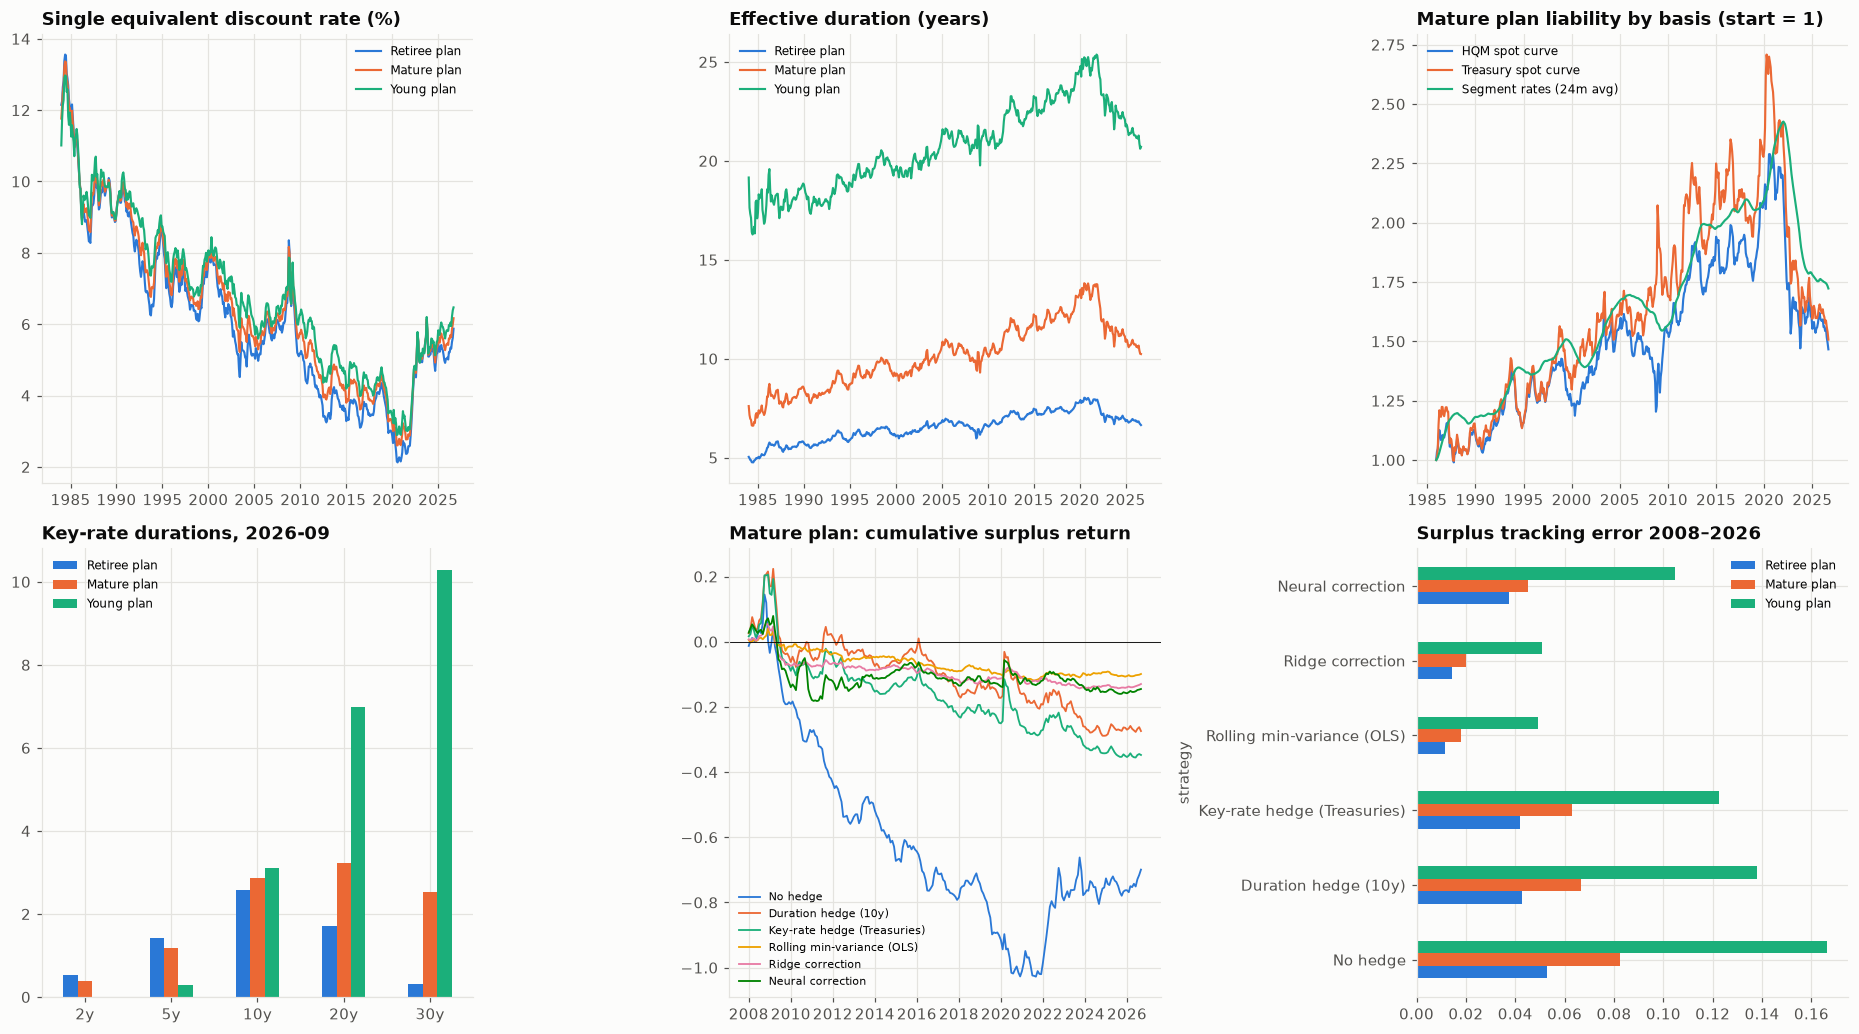

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
a = ax[0, 0]
for (k, v), col in zip(VAL.items(), PALETTE):
    a.plot(v.index.to_timestamp(), v["ser"] * 100, color=col, label=k, lw=1.4)
a.set_title("Single equivalent discount rate (%)")
a.legend(fontsize=8)
a = ax[0, 1]
for (k, v), col in zip(VAL.items(), PALETTE):
    a.plot(v.index.to_timestamp(), v["duration"], color=col, label=k, lw=1.4)
a.set_title("Effective duration (years)")
a.legend(fontsize=8)
a = ax[0, 2]
for c_, col in zip(BASIS.columns, PALETTE):
    a.plot(
        BASIS.index.to_timestamp(),
        BASIS[c_] / BASIS[c_].iloc[0],
        color=col,
        label=c_,
        lw=1.4,
    )
a.set_title("Mature plan liability by basis (start = 1)")
a.legend(fontsize=8)
a = ax[1, 0]
kr = SNAP[[f"krd_{k}" for k in KEY_TENORS]]
kr.columns = [f"{k}y" for k in KEY_TENORS]
kr.T.plot.bar(ax=a, color=PALETTE[:3], rot=0)
a.set_title(f"Key-rate durations, {last}")
a.legend(fontsize=8)
a = ax[1, 1]
for (k, s), col in zip(RESULTS["Mature plan"].items(), PALETTE):
    a.plot(
        s.loc[TEST_START:].index.to_timestamp(),
        s.loc[TEST_START:].cumsum(),
        color=col,
        label=k,
        lw=1.2,
    )
a.axhline(0, color=INK, lw=0.6)
a.set_title("Mature plan: cumulative surplus return")
a.legend(fontsize=7)
a = ax[1, 2]
te = RES["tracking error (ann.)"].unstack(0)
te.plot.barh(ax=a, color=PALETTE[:3])
a.set_title("Surplus tracking error 2008–2026")
a.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "01_liability_discounting_ldi")
plt.show()

In [12]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Single equivalent rate by plan (%)",
        "Mature plan liability by basis",
        "Surplus tracking error by strategy (2008–2026)",
        "Mature plan: cumulative surplus return",
    ),
)
for (k, v), col in zip(VAL.items(), PALETTE):
    dash.add_trace(
        go.Scatter(
            x=v.index.to_timestamp(),
            y=v["ser"] * 100,
            name=k,
            line=dict(color=col),
        ),
        1,
        1,
    )
for c_, col in zip(BASIS.columns, PALETTE[3:]):
    dash.add_trace(
        go.Scatter(
            x=BASIS.index.to_timestamp(),
            y=BASIS[c_] / BASIS[c_].iloc[0],
            name=c_,
            line=dict(color=col),
        ),
        1,
        2,
    )
for plan, col in zip(PLANS, PALETTE):
    tab = RES.loc[plan]
    dash.add_trace(
        go.Bar(
            x=tab.index,
            y=tab["tracking error (ann.)"],
            name=plan,
            marker_color=col,
            showlegend=False,
        ),
        2,
        1,
    )
for (k, s), col in zip(RESULTS["Mature plan"].items(), PALETTE):
    s = s.loc[TEST_START:]
    dash.add_trace(
        go.Scatter(
            x=s.index.to_timestamp(),
            y=s.cumsum(),
            name=k,
            line=dict(color=col, dash="dot"),
        ),
        2,
        2,
    )
dash.update_layout(
    height=900,
    width=1400,
    template="simple_white",
    title="Pension liability discounting and LDI hedges",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 11. Reading the results and limitations

**The discount rate drives everything.** On the HQM curve, the mature plan's single equivalent rate was 13.4% in mid-1984, a low of 2.6% in August 2020, and 6.2% in September 2026. Its effective duration rose from about 7 to almost 14 years as rates fell, and is back to 10.2 years today.

The same profile of payments was worth about 2.8 times as much at the 2020 low as in mid-1984. In 2022 the liability fell by 17% for the retiree plan, 24% for the mature plan and 37% for the young plan, with no change in the members.

**Liability snapshot, September 2026**

| Plan | Value (per unit of payments) | Single equivalent rate | Effective duration | KRD 2y | KRD 5y | KRD 10y | KRD 20y | KRD 30y |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Retiree plan | 0.62 | 5.9% | 6.6 | 0.5 | 1.4 | 2.6 | 1.7 | 0.3 |
| Mature plan | 0.42 | 6.2% | 10.2 | 0.4 | 1.2 | 2.9 | 3.2 | 2.5 |
| Young plan | 0.19 | 6.5% | 20.7 | 0.0 | 0.3 | 3.1 | 7.0 | 10.3 |

The key-rate durations add up to the effective duration, which is a useful check. A young plan's risk sits almost entirely beyond 20 years, where Treasuries are thin and the HQM curve is extrapolated.

**The basis matters as much as the rate.** For the mature plan today:

- Treasury discounting gives a liability 10% higher than the HQM curve.
- The 24-month segment-rate basis gives a value 6% higher, because it still averages in the lower rates of 2024–2025.
- The segment basis is also far smoother. Its annualised volatility is 1.6%, against 7.3% for the HQM curve and 8.6% for Treasuries. In 2022 it fell 11%, against 28% on the market curves.

That smoothing is deliberate in minimum-funding rules. It also means a plan can look adequately funded for contribution purposes while its accounting and settlement values move much more.

**Hedging, 2008–2026 (out of time, monthly rebalanced)**

| Strategy | Retiree: tracking error | Retiree: variance removed | Mature: tracking error | Mature: variance removed | Young: tracking error | Young: variance removed |
| --- | --- | --- | --- | --- | --- | --- |
| No hedge | 5.3% | — | 8.3% | — | 16.6% | — |
| Duration hedge (10y) | 4.3% | 35% | 6.7% | 35% | 13.8% | 31% |
| Key-rate hedge (Treasuries) | 4.2% | 37% | 6.3% | 42% | 12.2% | 46% |
| Rolling min-variance (OLS) | **1.2%** | **95%** | **1.8%** | **95%** | **4.9%** | **91%** |
| Ridge correction | 1.4% | 93% | 2.0% | 94% | 5.1% | 91% |
| Neural correction | 3.7% | 50% | 4.5% | 70% | 10.5% | 61% |

**Treasuries alone hedge less than half the risk.** A Treasury hedge matched exactly on duration or on key rates removes only 31–46% of the surplus variance. The reason shows up in 2008: Treasury yields fell while corporate yields rose. The Treasury-hedged mature plan gained 21% of liabilities that year, a large and unwanted move in the opposite direction.

The HQM discount curve is a corporate curve, so the credit spread is part of the liability's risk. A Treasury hedge cannot see it.

**Adding corporate bonds closes most of the gap.** The rolling regression and the ridge correction both learn to hold roughly the liability value in investment-grade corporate bonds (LQD weights of 0.6–1.9), with Treasuries completing the duration. They remove 91–95% of the surplus variance. The worst 12-month surplus loss for the mature plan falls from 34% unhedged and 28% with Treasuries to 6% with the rolling regression.

**The cost of a Treasury hedge is visible in the drift.** Every Treasury-only strategy loses about 1.5–2% of liabilities a year against the HQM liability. The liability accretes at a corporate yield, while Treasuries earn less. Holding corporate bonds earns most of that spread back.

**The neural network adds nothing here.** Its state-dependent correction removes 50–70% of the variance: better than Treasuries alone, but well behind the plain regressions. With about 65 monthly observations in the first training window and 290 by the end, there is too little data for a network to learn reliably how hedge ratios should depend on the rate level, the spread or the slope. A simple regression that adds credit exposure captures nearly all the available improvement. The neural results were also unstable before clipping, early stopping and seed averaging were added.

**Limitations**

- The member data are stylised (Makeham mortality, flat nominal pensions, no new accruals), so the payment profiles are representative rather than any real plan's.
- HQM and Treasury rates are monthly averages, and LQD is averaged by month to match. True month-end hedging would be noisier.
- Treasury zeros are priced off a bootstrapped curve, not traded STRIPS, and there are no transaction costs, repo financing or swap overlays.
- The segment-rate basis omits the legal corridor around 25-year average rates.
- LQD has a shorter duration than the liabilities and its own index rules. A long-corporate portfolio or credit derivatives would change the credit hedge.

In [13]:
SNAP.to_csv(OUT_DIR / "liability_snapshot.csv")
BASIS_TAB.to_csv(OUT_DIR / "discount_basis_comparison.csv")
RES.to_csv(OUT_DIR / "hedge_backtest.csv")
AVG_W.to_csv(OUT_DIR / "average_hedge_weights.csv")
pd.concat(VAL, names=["plan"]).to_csv(OUT_DIR / "liability_history.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_liability_discounting_ldi.png, average_hedge_weights.csv, dashboard.html, dashboard.png, discount_basis_comparison.csv, hedge_backtest.csv, liability_history.csv, liability_snapshot.csv


## References

### Finance and regulation

- International Accounting Standards Board. (2011). *IAS 19 Employee benefits*. IFRS Foundation. https://www.ifrs.org/issued-standards/list-of-standards/ias-19-employee-benefits/
- Leibowitz, M. L., Kogelman, S., & Bader, L. N. (1994). Funding ratio return. *The Journal of Portfolio Management, 21*(1), 39–47. https://doi.org/10.3905/jpm.1994.409495
- Ho, T. S. Y. (1992). Key rate durations: Measures of interest rate risks. *The Journal of Fixed Income, 2*(2), 29–44. https://doi.org/10.3905/jfi.1992.408049
- Litterman, R., & Scheinkman, J. (1991). Common factors affecting bond returns. *The Journal of Fixed Income, 1*(1), 54–61. https://doi.org/10.3905/jfi.1991.692347
- Novy-Marx, R., & Rauh, J. (2011). Public pension promises: How big are they and what are they worth? *The Journal of Finance, 66*(4), 1211–1249. https://doi.org/10.1111/j.1540-6261.2011.01664.x
- Dickson, D. C. M., Hardy, M. R., & Waters, H. R. (2020). *Actuarial mathematics for life contingent risks* (3rd ed.). Cambridge University Press. https://doi.org/10.1017/9781108784184

### Machine learning and deep learning

- Ederington, L. H. (1979). The hedging performance of the new futures markets. *The Journal of Finance, 34*(1), 157–170. https://doi.org/10.1111/j.1540-6261.1979.tb02077.x
- Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634
- Buehler, H., Gonon, L., Teichmann, J., & Wood, B. (2019). Deep hedging. *Quantitative Finance, 19*(8), 1271–1291. https://doi.org/10.1080/14697688.2019.1571683